# Opdracht 2: Voorspel verhuuraantallen

**Teamnaam: Bakabana pindasaus**

Aroetin Avanesi, aroetin 25103865

Moreo Rahiembaks, moreorahiembaks, 25107607

Kaylim Taai, kaylimtaai, 24093157

## Inhoudsopgave
1. Inleiding
2. Exploratieve Data Analyse
3. Time series feature engineering
4. Modelleren
5. Bevindingen
6. Conclusie en aanbevelingen
7. Referenties

## 1. Inleiding

CityBike verhuurt fietsen op verschillende locaties in een grote stad. Klanten kunnen op ieder moment van de dag een fiets huren, bijvoorbeeld om naar hun werk te gaan, om de stad te bekijken of gewoon om een stukje te fietsen. Voor CityBike is het daarom belangrijk om te weten hoeveel fietsen er op ieder moment nodig zijn. Staan er te weinig fietsen, dan kan een klant geen fiets huren en loopt CityBike omzet mis. Staan er juist te veel fietsen op één plek, dan worden de fietsen en stallingsplaatsen niet goed benut.

Wat ons opviel toen we de data bekeken, is dat deze sterk lijkt op de bekende Bike Sharing dataset van Capital Bikeshare in Washington D.C. (Fanaee-T & Gama, 2014). De kolommen, de periode (2011 en 2012) en de feestdagen komen namelijk precies overeen. Dat is handig, want zo kunnen we de genormaliseerde weerkolommen terugrekenen naar echte eenheden (zie 2.2) en opvallende momenten in de data verklaren.

In dit notebook beginnen we met een verkenning van de data (hoofdstuk 2). Daarna maken we nieuwe features op basis van de tijd (hoofdstuk 3) en vergelijken we verschillende modellen (hoofdstuk 4). Vervolgens zetten we de resultaten op een rij (hoofdstuk 5) en sluiten we af met onze conclusie en een advies aan CityBike (hoofdstuk 6).

### 1.1 Probleemstelling

CityBike wil weten **hoeveel fietsen er per uur worden verhuurd** (`cnt`). We trainen op de periode van 1 januari 2011 tot en met 30 november 2012 en voorspellen de periode van **1 tot en met 19 december 2012**.

Dit is een regressieprobleem, maar wel een bijzonder soort: de data is een tijdreeks. Dat heeft drie gevolgen voor onze aanpak:

1. **De volgorde in de tijd is belangrijk.** Bij het valideren mogen we nooit trainen op data die na de validatieperiode ligt. Anders "kijkt" het model immers in de toekomst. Daarom gebruiken we geen gewone KFold, maar een cross-validation die rekening houdt met de tijd (hoofdstuk 4.1).
2. **We voorspellen 19 dagen vooruit.** Voor de testperiode kennen we `cnt` niet. Een feature als "het aantal verhuringen van een uur geleden" kunnen we daar dus niet gebruiken. Daar houden we rekening mee bij de feature engineering (hoofdstuk 3.3).
3. **De score is de RMSE.** Kaggle beoordeelt ons op de Root Mean Squared Error, oftewel hoeveel fietsen we er gemiddeld naast zitten, waarbij grote fouten zwaarder tellen. De minimumeis is een RMSE van 80.

Uiteindelijk willen we een model dat CityBike helpt om de fietsen beter te verdelen, zodat klanten zo vaak mogelijk een fiets kunnen huren wanneer ze die nodig hebben.

## 2. Exploratieve Data Analyse

### 2.1 Data inladen

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Vaste kleuren, zodat dezelfde groep in iedere grafiek dezelfde kleur heeft
BLUE = "#257de0"
ORANGE = "#f47230"
sns.set_theme(style="whitegrid")

TARGET = "cnt"
WEATHER_COLS = ["temp", "atemp", "hum", "windspeed"]


class BikeData:
    """Laadt de datasets van de Kaggle competitie Voorspel verhuuraantallen."""

    def __init__(self, data_dir="voorspel-verhuuraantallen-2026"):
        # Map waarin de csv bestanden staan (in de GitHub repo)
        self.data_dir = Path(data_dir)
        self.train = None
        self.test = None
        self.submission = None

    def load(self):
        """Leest de drie csv bestanden in en zet date_hour om naar datetime."""
        self.train = pd.read_csv(self.data_dir / "train.csv",
                                 parse_dates=["date_hour"])
        self.test = pd.read_csv(self.data_dir / "test.csv",
                                parse_dates=["date_hour"])
        self.submission = pd.read_csv(
            self.data_dir / "sample_submission.csv"
        )
        return self

    def check_shapes(self):
        """Toont het aantal rijen en kolommen en de periode per dataset."""
        for name, df in [("train", self.train), ("test", self.test)]:
            print(f"{name:<6} {df.shape}  "
                  f"{df['date_hour'].min()} t/m {df['date_hour'].max()}")
        print(f"submission {self.submission.shape}")


data = BikeData().load()
data.check_shapes()
data.train.head()

train  (16637, 8)  2011-01-01 00:00:00 t/m 2012-11-30 23:00:00
test   (456, 7)  2012-12-01 00:00:00 t/m 2012-12-19 23:00:00
submission (456, 2)


,date_hour,holiday,weathersit,temp,atemp,hum,windspeed,cnt
0,2011-01-01 00:00:00,0,1,0.24,0.2879,0.81,0.0,16
1,2011-01-01 01:00:00,0,1,0.22,0.2727,0.80,0.0,40
2,2011-01-01 02:00:00,0,1,0.22,0.2727,0.80,0.0,32
3,2011-01-01 03:00:00,0,1,0.24,0.2879,0.75,0.0,13
4,2011-01-01 04:00:00,0,1,0.24,0.2879,0.75,0.0,1


### 2.2 Uitleg kolommen

De weerkolommen zijn genormaliseerd, oftewel omgezet naar een waarde tussen 0 en 1. Volgens de beschrijving van de originele dataset (Fanaee-T, 2013) kun je ze op de manier hieronder terugrekenen naar echte eenheden. Dat doen we in de grafieken, omdat "20 °C" nu eenmaal makkelijker te lezen is dan "0,6".

| Kolom | Betekenis | Type | Terugrekenen |
|---|---|---|---|
| `date_hour` | Datum en uur van de meting | datetime | |
| `holiday` | 1 = officiële feestdag in Washington D.C., 0 = geen feestdag | binair | |
| `weathersit` | Weertype: 1 = helder, 2 = mist of bewolkt, 3 = lichte regen of sneeuw, 4 = zware regen, hagel of sneeuw | categorisch (geordend) | |
| `temp` | Temperatuur | continu | $t = temp \cdot 47 - 8$ (°C) |
| `atemp` | Gevoelstemperatuur | continu | $t = atemp \cdot 66 - 16$ (°C) |
| `hum` | Luchtvochtigheid | continu | $hum \cdot 100$ (%) |
| `windspeed` | Windsnelheid | continu | $windspeed \cdot 67$ (km/u) |
| `cnt` | **Target:** aantal verhuurde fietsen in dat uur | geheel getal | |

Een kanttekening bij `weathersit`: het is een getal, maar eigenlijk een categorie. Wel een categorie met een volgorde, want hoe hoger het getal, hoe slechter het weer. Een model mag daarom ook rekenen met "hoger = slechter".

In [3]:
def describe_columns(df):
    """Datatype, aantal unieke waarden, bereik en voorbeelden per kolom."""
    return pd.DataFrame({
        "datatype": df.dtypes.astype(str),
        "uniek": df.nunique(),
        "minimum": df.min(),
        "maximum": df.max(),
        "voorbeeld": df.iloc[0],
    })


describe_columns(data.train)

,datatype,uniek,minimum,maximum,voorbeeld
date_hour,datetime64[us],16637,2011-01-01 00:00:00,2012-11-30 23:00:00,2011-01-01 00:00:00
holiday,int64,2,0,1,0
weathersit,int64,4,1,4,1
temp,float64,50,0.02,1.0,0.24
atemp,float64,65,0.0,1.0,0.2879
hum,float64,89,0.0,1.0,0.81
windspeed,float64,30,0.0,0.8507,0.0
cnt,int64,867,1,977,16


### 2.3 Datatypes en basisstatistieken

In [9]:
def show_overview(df):
    """Toont het formaat, ontbrekende waarden en dubbele rijen."""
    print(f"Rijen: {df.shape[0]}, kolommen: {df.shape[1]}")
    print(f"Ontbrekende waarden: {df.isna().sum().sum()}")
    print(f"Dubbele rijen: {df.duplicated().sum()}")


show_overview(data.train)
print(data.train.dtypes)
# Gemiddelde, spreiding, minimum, kwartielen en maximum
data.train.describe().round(3)

Rijen: 16637, kolommen: 8
Ontbrekende waarden: 0
Dubbele rijen: 0
date_hour     datetime64[us]
holiday                int64
weathersit             int64
temp                 float64
atemp                float64
hum                  float64
windspeed            float64
cnt                    int64
dtype: object


,date_hour,holiday,weathersit,temp,atemp,hum,windspeed,cnt
count,16637,16637.000,16637.000,16637.000,16637.000,16637.000,16637.000,16637.000
mean,2011-12-18 02:20:08.294764,0.029,1.416,0.505,0.483,0.625,0.190,190.477
min,2011-01-01 00:00:00,0.000,1.000,0.020,0.000,0.000,0.000,1.000
25%,2011-06-27 05:00:00,0.000,1.000,0.340,0.333,0.470,0.104,41.000
50%,2011-12-18 06:00:00,0.000,1.000,0.520,0.500,0.620,0.194,143.000
75%,2012-06-09 02:00:00,0.000,2.000,0.660,0.621,0.780,0.254,282.000
max,2012-11-30 23:00:00,1.000,4.000,1.000,1.000,1.000,0.851,977.000
std,NaN,0.167,0.637,0.192,0.172,0.193,0.122,182.027


In [ ]:
def count_values(df, columns):
    """Aantal en percentage per waarde voor categorische kolommen."""
    tables = []
    for col in columns:
        counts = df[col].value_counts().sort_index()
        tables.append(pd.DataFrame({
            "kolom": col,
            "waarde": counts.index,
            "aantal": counts.values,
            "percentage": (counts.values / len(df) * 100).round(2),
        }))
    return pd.concat(tables, ignore_index=True)


count_values(data.train, ["holiday", "weathersit"])

,kolom,waarde,aantal,percentage
0,holiday,0,16160,97.13
1,holiday,1,477,2.87
2,weathersit,1,11078,66.59
3,weathersit,2,4207,25.29
4,weathersit,3,1349,8.11
5,weathersit,4,3,0.02


Verwacht aantal uren: 16800
Ontbrekende uren:     163
Laagste waarde cnt:   1


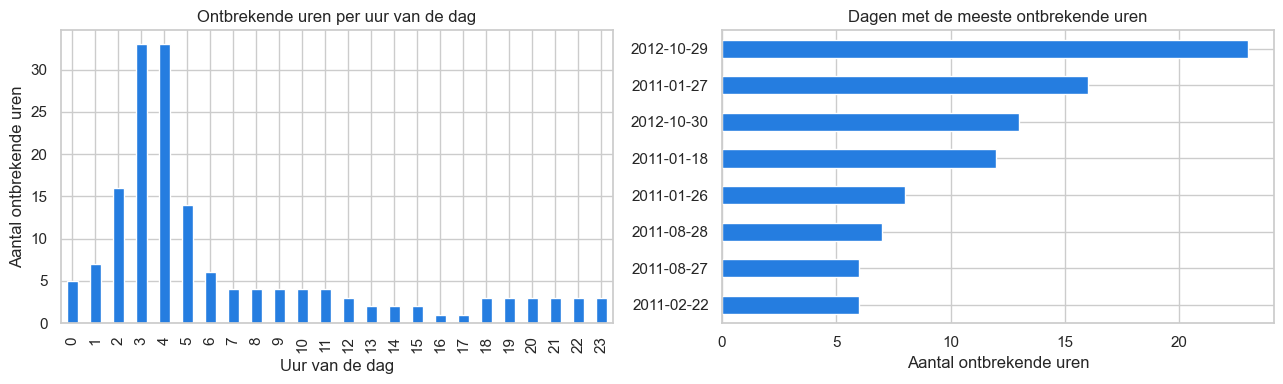

In [6]:
def find_missing_hours(df):
    """Geeft alle uren terug die in de reeks ontbreken."""
    full_range = pd.date_range(df["date_hour"].min(),
                               df["date_hour"].max(), freq="h")
    return full_range.difference(df["date_hour"])


missing = find_missing_hours(data.train)
print(f"Verwacht aantal uren: {len(missing) + len(data.train)}")
print(f"Ontbrekende uren:     {len(missing)}")
print(f"Laagste waarde cnt:   {data.train[TARGET].min()}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
pd.Series(missing.hour).value_counts().sort_index().plot(
    kind="bar", ax=axes[0], color=BLUE)
axes[0].set_title("Ontbrekende uren per uur van de dag")
axes[0].set_xlabel("Uur van de dag")
axes[0].set_ylabel("Aantal ontbrekende uren")

pd.Series(missing.date).value_counts().head(8).sort_values().plot(
    kind="barh", ax=axes[1], color=BLUE)
axes[1].set_title("Dagen met de meeste ontbrekende uren")
axes[1].set_xlabel("Aantal ontbrekende uren")
plt.tight_layout()
plt.show()

In [7]:
def check_weather(df):
    """Telt verdachte waarden in de weerkolommen per dag."""
    temp_c = df["temp"] * 47 - 8
    atemp_c = df["atemp"] * 66 - 16
    checks = {
        "hum == 0": df["hum"] == 0,
        "windspeed == 0": df["windspeed"] == 0,
        "|temp - atemp| > 10 °C": (temp_c - atemp_c).abs() > 10,
    }
    for name, mask in checks.items():
        days = df.loc[mask, "date_hour"].dt.date.value_counts()
        print(f"{name:<24} {mask.sum():>5} uren, "
              f"vaakst op: {days.head(3).to_dict()}")


check_weather(data.train)

hum == 0                    22 uren, vaakst op: {datetime.date(2011, 3, 10): 22}
windspeed == 0            2072 uren, vaakst op: {datetime.date(2011, 10, 7): 20, datetime.date(2012, 11, 26): 16, datetime.date(2011, 12, 11): 15}
|temp - atemp| > 10 °C      37 uren, vaakst op: {datetime.date(2012, 8, 17): 24, datetime.date(2011, 7, 21): 7, datetime.date(2011, 7, 22): 6}


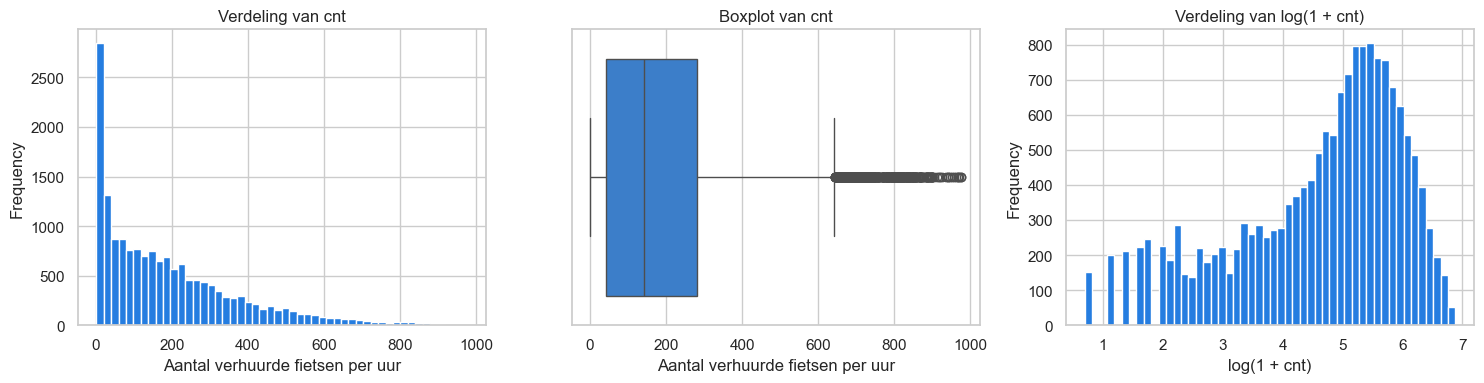

Scheefheid (skewness): 1.28
Outliers volgens de IQR-regel (cnt > 644): 486


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
data.train[TARGET].plot(kind="hist", bins=50, ax=axes[0], color=BLUE)
axes[0].set_title("Verdeling van cnt")
axes[0].set_xlabel("Aantal verhuurde fietsen per uur")

sns.boxplot(x=data.train[TARGET], ax=axes[1], color=BLUE)
axes[1].set_title("Boxplot van cnt")
axes[1].set_xlabel("Aantal verhuurde fietsen per uur")

np.log1p(data.train[TARGET]).plot(kind="hist", bins=50, ax=axes[2],
                                  color=BLUE)
axes[2].set_title("Verdeling van log(1 + cnt)")
axes[2].set_xlabel("log(1 + cnt)")
plt.tight_layout()
plt.show()

q1, q3 = data.train[TARGET].quantile([0.25, 0.75])
upper = q3 + 1.5 * (q3 - q1)
print(f"Scheefheid (skewness): {data.train[TARGET].skew():.2f}")
print(f"Outliers volgens de IQR-regel (cnt > {upper:.0f}): "
      f"{(data.train[TARGET] > upper).sum()}")

**Wat hebben we gecontroleerd en wat zien we?**

Eerst hebben we gekeken naar de datatypes en basisstatistieken. Daarna hebben we gecontroleerd of er uren ontbreken en of er vreemde waarden in het weer zitten. Tot slot hebben we de verdeling van `cnt` bekeken.

* **Datatypes.** De dataset heeft 16.637 rijen en 8 kolommen: `date_hour` (datetime), `holiday`, `weathersit` en `cnt` (gehele getallen) en vier weerkolommen (kommagetallen). Er zijn geen lege cellen en geen dubbele rijen of tijdstippen.
* **Er ontbreken 163 uren.** Er staan dan wel geen lege cellen in de data, maar bij een tijdreeks kunnen er ook hele rijen ontbreken. Van 1 januari 2011 tot en met 30 november 2012 zouden er 16.800 uren moeten zijn. Wat ons hierbij opviel, is dat `cnt` nooit 0 is. Het minimum is namelijk 1. De vraag is dan: wat gebeurt er met een uur waarin niemand een fiets huurt? Als we kijken wanneer de uren ontbreken, zien we dat dit bijna altijd 's nachts is, vooral tussen 2:00 en 5:00. Onze verklaring is dat zo'n uur gewoon niet in de data is opgenomen. Een ontbrekend uur betekent dus waarschijnlijk **0 verhuringen**, en niet dat de meting mist.
* **Twee grote gaten hebben een verklaring.** Op 29 en 30 oktober 2012 ontbreken 36 uren. Toen ging Capital Bikeshare dicht vanwege orkaan Sandy (Bates Area Civic Association, 2012). Ook in januari 2011 en op 27 en 28 augustus 2011, toen orkaan Irene langs de oostkust trok, ontbreken veel uren. Dit zijn uitzonderingen die het model niet hoeft te leren.
* **`weathersit` 4 komt maar 3 keer voor.** Van zo weinig voorbeelden kan een model niets leren (zie 2.7).
* **Er zitten fouten in de weerdata.** Een luchtvochtigheid van 0% kan niet, maar komt op 10 maart 2011 een hele dag voor. Daarnaast ligt `atemp` op 17 augustus 2012 de hele dag meer dan 10 °C onder `temp`. Dit zijn meetfouten die we in 2.7 herstellen. Een windsnelheid van 0 komt 2.072 keer voor. Dat kan windstil zijn, maar ook een ontbrekende meting. Omdat we dat niet kunnen controleren, laten we deze waarden staan.
* **`cnt` is scheef naar rechts verdeeld** (skewness 1,28). De meeste uren hebben weinig verhuringen en er zijn een paar uren met heel veel. De IQR-regel noemt 486 van die drukke uren outliers, maar dat zijn gewoon de spitsuren. Die verwijderen we dus niet. Na een log-transformatie is de verdeling een stuk minder scheef. Of dat de voorspellingen beter maakt, proberen we uit bij het modelleren (hoofdstuk 4).

### 2.4 Tijdserie-elementen en patronen

We voegen eerst een aantal tijdselementen toe aan de data: uur, weekdag, maand, jaar en `workingday`. Een werkdag is een dag die geen zaterdag, zondag of feestdag is. We verwachten namelijk dat woon-werkverkeer een heel ander patroon heeft dan recreatief fietsen. Daarna bekijken we eerst de hele reeks en de groei per jaar. Vervolgens kijken we naar het dagpatroon en het weekpatroon, en tot slot naar hoe december eruitziet.

In [10]:
DAY_NAMES = ["ma", "di", "wo", "do", "vr", "za", "zo"]


def add_time_elements(df):
    """Voegt kalenderkolommen toe op basis van date_hour."""
    df = df.copy()
    moment = df["date_hour"]
    df["hour"] = moment.dt.hour
    df["weekday"] = moment.dt.dayofweek          # 0 = maandag
    df["month"] = moment.dt.month
    df["year"] = moment.dt.year
    df["date"] = moment.dt.normalize()
    df["is_weekend"] = (df["weekday"] >= 5).astype(int)
    # Werkdag = geen weekend en geen feestdag
    df["workingday"] = ((df["is_weekend"] == 0)
                        & (df["holiday"] == 0)).astype(int)
    return df


train = add_time_elements(data.train)
train[["date_hour", "hour", "weekday", "month", "year", "workingday"]].head()

,date_hour,hour,weekday,month,year,workingday
0,2011-01-01 00:00:00,0,5,1,2011,0
1,2011-01-01 01:00:00,1,5,1,2011,0
2,2011-01-01 02:00:00,2,5,1,2011,0
3,2011-01-01 03:00:00,3,5,1,2011,0
4,2011-01-01 04:00:00,4,5,1,2011,0


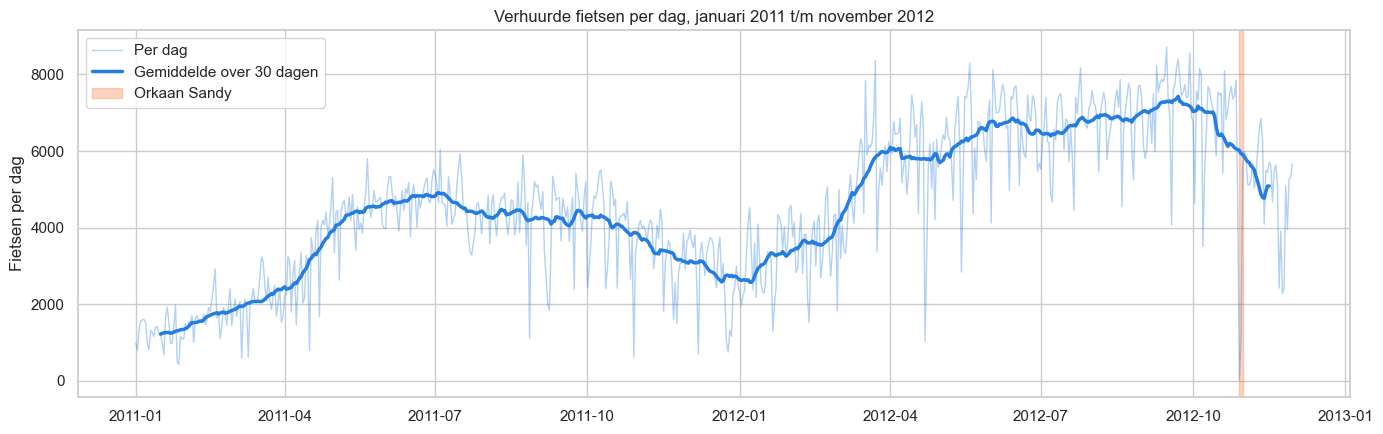

In [11]:
daily = train.groupby("date")[TARGET].sum()

fig, ax = plt.subplots(figsize=(14, 4.5))
ax.plot(daily.index, daily.values, color=BLUE, alpha=0.35, linewidth=1,
        label="Per dag")
ax.plot(daily.index, daily.rolling(30, center=True).mean(), color=BLUE,
        linewidth=2.5, label="Gemiddelde over 30 dagen")
# Orkaan Sandy markeren
ax.axvspan(pd.Timestamp("2012-10-29"), pd.Timestamp("2012-10-31"),
           color=ORANGE, alpha=0.3, label="Orkaan Sandy")
ax.set_title("Verhuurde fietsen per dag, januari 2011 t/m november 2012")
ax.set_ylabel("Fietsen per dag")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

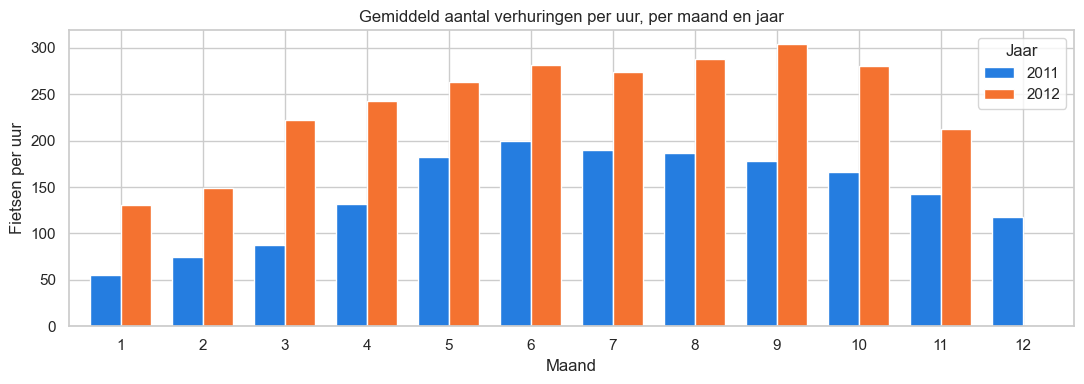

year,2011,2012,groei
month,,,
1,55.51,130.56,2.35
2,74.29,149.04,2.01
3,87.73,221.90,2.53
4,131.95,242.65,1.84
5,182.56,263.26,1.44
6,199.32,281.71,1.41
7,189.97,273.67,1.44
8,186.99,288.31,1.54
9,177.71,303.57,1.71


In [12]:
monthly = train.pivot_table(index="month", columns="year", values=TARGET,
                            aggfunc="mean")
monthly["groei"] = monthly[2012] / monthly[2011]

fig, ax = plt.subplots(figsize=(11, 4))
monthly[[2011, 2012]].plot(kind="bar", ax=ax, color=[BLUE, ORANGE],
                           width=0.75)
ax.set_title("Gemiddeld aantal verhuringen per uur, per maand en jaar")
ax.set_xlabel("Maand")
ax.set_ylabel("Fietsen per uur")
ax.legend(title="Jaar")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

monthly.round(2)

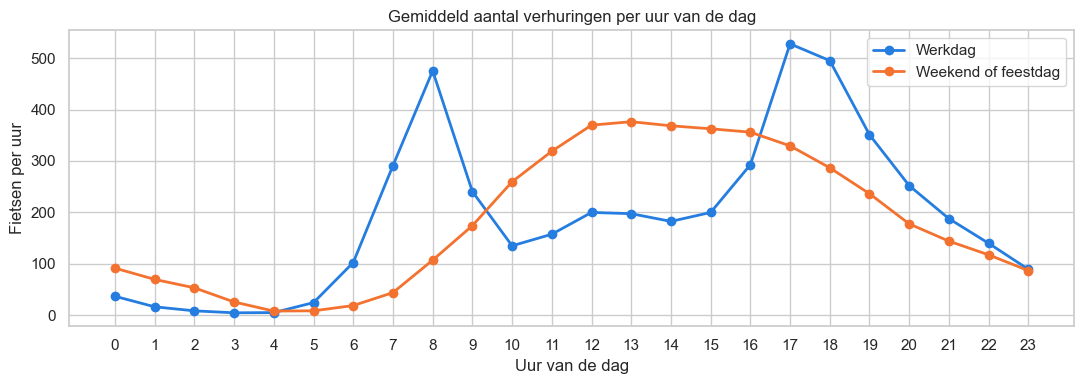

Drukste uren op een werkdag:
hour
17    528.0
18    495.0
8     475.0
Name: 1, dtype: float64


In [13]:
hourly = train.pivot_table(index="hour", columns="workingday",
                           values=TARGET, aggfunc="mean")

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(hourly.index, hourly[1], color=BLUE, linewidth=2, marker="o",
        label="Werkdag")
ax.plot(hourly.index, hourly[0], color=ORANGE, linewidth=2, marker="o",
        label="Weekend of feestdag")
ax.set_title("Gemiddeld aantal verhuringen per uur van de dag")
ax.set_xlabel("Uur van de dag")
ax.set_ylabel("Fietsen per uur")
ax.set_xticks(range(24))
ax.legend()
plt.tight_layout()
plt.show()

print("Drukste uren op een werkdag:")
print(hourly[1].sort_values(ascending=False).head(3).round(0))

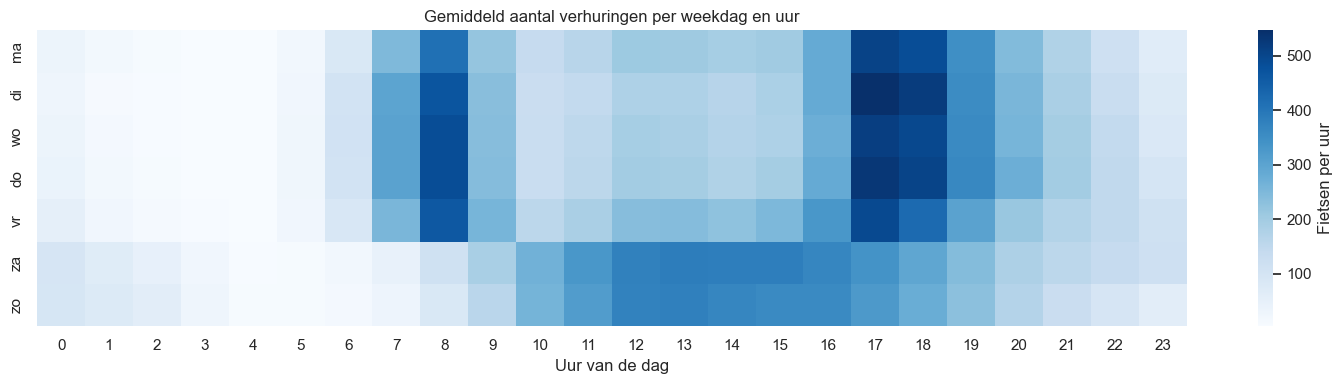

ma    184.7
di    191.0
wo    191.8
do    197.2
vr    196.8
za    191.8
zo    180.0
Name: cnt, dtype: float64

In [14]:
heat = train.pivot_table(index="weekday", columns="hour", values=TARGET,
                         aggfunc="mean")
heat.index = DAY_NAMES

plt.figure(figsize=(15, 4))
sns.heatmap(heat, cmap="Blues", cbar_kws={"label": "Fietsen per uur"})
plt.title("Gemiddeld aantal verhuringen per weekdag en uur")
plt.xlabel("Uur van de dag")
plt.ylabel("")
plt.tight_layout()
plt.show()

train.groupby("weekday")[TARGET].mean().set_axis(DAY_NAMES).round(1)

In [15]:
def mean_per_day(daily_counts, start, end):
    """Gemiddeld aantal verhuringen per dag tussen start en end."""
    return daily_counts[start:end].mean()


nov_2011 = mean_per_day(daily, "2011-11-01", "2011-11-30")
dec_2011 = mean_per_day(daily, "2011-12-01", "2011-12-19")
nov_2012 = mean_per_day(daily, "2012-11-01", "2012-11-30")
ratio = dec_2011 / nov_2011

print(f"November 2011:            {nov_2011:7.0f} per dag")
print(f"1 t/m 19 december 2011:   {dec_2011:7.0f} per dag "
      f"({ratio:.0%} van november)")
print(f"November 2012:            {nov_2012:7.0f} per dag")
print(f"Verwachting dec 2012:     {nov_2012 * ratio:7.0f} per dag, "
      f"ongeveer {nov_2012 * ratio / 24:.0f} per uur")

November 2011:               3406 per dag
1 t/m 19 december 2011:      3220 per dag (95% van november)
November 2012:               5089 per dag
Verwachting dec 2012:        4812 per dag, ongeveer 200 per uur


**Wat zien we?**

* **Er is een duidelijke groei.** In de eerste grafiek staan de verhuringen per dag, met een gemiddelde over 30 dagen erdoorheen. In 2012 worden per uur gemiddeld 241 fietsen verhuurd, tegen 144 in 2011. Dat is 68% meer. Als we per maand vergelijken, valt op dat de groei het grootst is in de wintermaanden aan het begin van het jaar. Maart 2012 is bijvoorbeeld 2,5 keer zo druk als maart 2011, terwijl de zomer van 2012 "maar" 1,4 keer zo druk is. Dit is de **trend** in de reeks.
* **Er is een seizoenspatroon per jaar.** In beide jaren is het druk van mei tot en met oktober en rustig in de winter. Januari is de rustigste maand. Het seizoen en de trend werken wel op elkaar in: de zomer van 2012 ligt veel hoger dan die van 2011.
* **Werkdagen en weekenden hebben een totaal ander dagpatroon.** Op werkdagen zijn er twee pieken: rond 8:00 (op weg naar het werk) en rond 17:00 en 18:00 (op weg naar huis). Op die momenten worden gemiddeld meer dan 450 fietsen per uur verhuurd. In het weekend en op feestdagen is er juist één brede bult tussen 11:00 en 17:00. Dat is recreatief gebruik. Een model moet dus niet alleen het uur kennen, maar ook weten of het een werkdag is.
* **Weekdagen lijken op elkaar.** De heatmap laat zien dat maandag tot en met vrijdag vrijwel hetzelfde patroon hebben, en dat zaterdag en zondag bij elkaar horen. Een indeling in werkdag en weekend vangt dus het grootste deel van het weekpatroon.
* **December is iets rustiger dan november.** De testperiode (1 t/m 19 december 2012) hebben we in 2012 nog niet gezien, wel in 2011. Toen lag 1 t/m 19 december op ongeveer 95% van november. Als dat in 2012 ook zo is, verwachten we in de testperiode ongeveer 4.800 verhuringen per dag, oftewel zo'n 200 per uur. Dit gebruiken we later als controle. Komen de voorspellingen van een model daar ver boven of onder, dan is er waarschijnlijk iets mis.

### 2.5 Relaties tussen de variabelen en cnt

In deze paragraaf onderzoeken we het verband tussen de onafhankelijke variabelen en `cnt`. Eerst kijken we naar de weerkolommen. Daarbij delen we de waarden op in groepen (bins) en tekenen we het gemiddelde per groep. Een scatterplot met 16.637 punten is namelijk niet goed te lezen. Het weer rekenen we daarbij terug naar echte eenheden (zie 2.2). Daarna kijken we of het effect van temperatuur verschilt per uur van de dag, en wat het weertype en feestdagen doen. Tot slot berekenen we welke kolommen het sterkst met `cnt` samenhangen.

Daarvoor gebruiken we twee soorten correlatie. Pearson meet alleen een rechtlijnig verband. Spearman kijkt naar de rangorde en vangt dus ook verbanden die wel stijgen of dalen, maar niet in een rechte lijn. Als Spearman veel hoger is dan Pearson, weten we dus dat een verband niet rechtlijnig is.

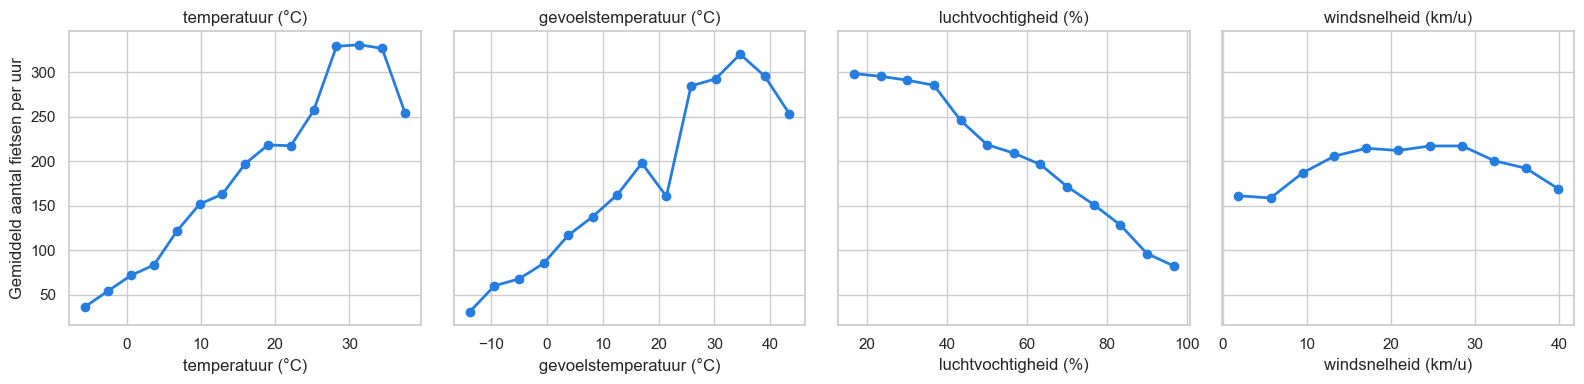

In [16]:
def to_real_units(df):
    """Rekent de genormaliseerde weerkolommen terug naar echte eenheden."""
    return pd.DataFrame({
        "temperatuur (°C)": df["temp"] * 47 - 8,
        "gevoelstemperatuur (°C)": df["atemp"] * 66 - 16,
        "luchtvochtigheid (%)": df["hum"] * 100,
        "windsnelheid (km/u)": df["windspeed"] * 67,
    })


def plot_binned_mean(df, columns, target, bins=15):
    """Gemiddelde target per bin voor iedere continue kolom."""
    fig, axes = plt.subplots(1, len(columns), figsize=(16, 4), sharey=True)
    for ax, col in zip(axes, columns):
        groups = pd.cut(df[col], bins=bins)
        means = df.groupby(groups, observed=True)[target].agg(
            ["mean", "size"])
        # Bins met heel weinig uren zijn onbetrouwbaar, die laten we weg
        means = means[means["size"] >= 30]
        centers = [interval.mid for interval in means.index]
        ax.plot(centers, means["mean"], color=BLUE, marker="o",
                linewidth=2)
        ax.set_title(col)
        ax.set_xlabel(col)
    axes[0].set_ylabel("Gemiddeld aantal fietsen per uur")
    plt.tight_layout()
    plt.show()


weather_real = to_real_units(train)
weather_real[TARGET] = train[TARGET]
plot_binned_mean(weather_real, weather_real.columns[:-1], TARGET)

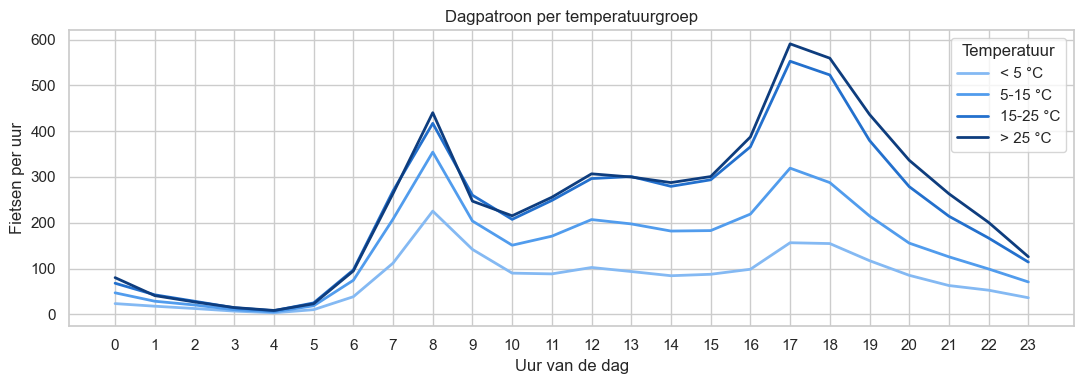

In [17]:
temp_groups = pd.cut(weather_real["temperatuur (°C)"],
                     bins=[-10, 5, 15, 25, 40],
                     labels=["< 5 °C", "5-15 °C", "15-25 °C", "> 25 °C"])
temp_hour = train.groupby([temp_groups, "hour"],
                          observed=True)[TARGET].mean().unstack(0)

fig, ax = plt.subplots(figsize=(11, 4))
# Licht naar donker blauw: hoe donkerder, hoe warmer
temp_hour.plot(ax=ax, linewidth=2,
               color=["#84b9f3", "#519ced", "#2370cd", "#0e3d7e"])
ax.set_title("Dagpatroon per temperatuurgroep")
ax.set_xlabel("Uur van de dag")
ax.set_ylabel("Fietsen per uur")
ax.set_xticks(range(24))
ax.legend(title="Temperatuur")
plt.tight_layout()
plt.show()

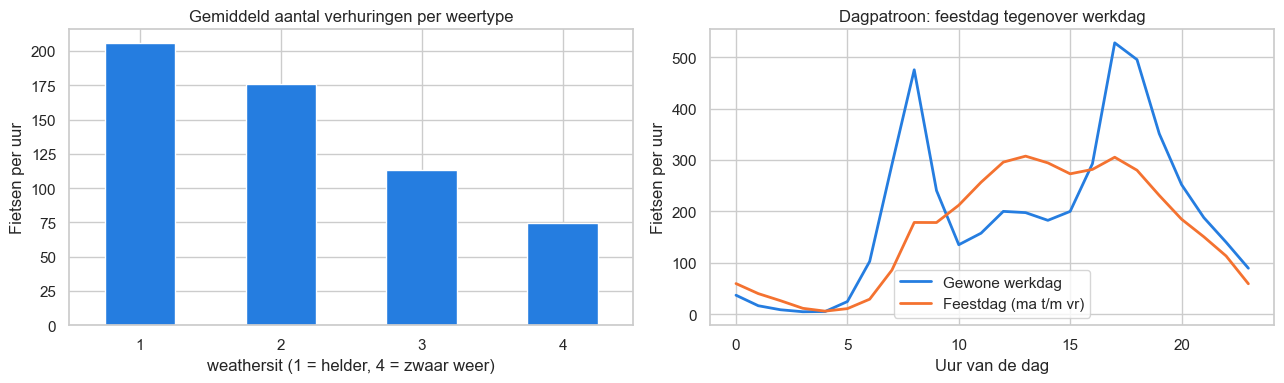

,mean,size
weathersit,,
1,205.4,11078
2,175.8,4207
3,113.5,1349
4,74.3,3


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Weertype: gemiddelde en aantal uren
weather_stats = train.groupby("weathersit")[TARGET].agg(["mean", "size"])
weather_stats["mean"].plot(kind="bar", ax=axes[0], color=BLUE)
axes[0].set_title("Gemiddeld aantal verhuringen per weertype")
axes[0].set_xlabel("weathersit (1 = helder, 4 = zwaar weer)")
axes[0].set_ylabel("Fietsen per uur")
axes[0].tick_params(axis="x", rotation=0)

# Feestdag tegenover gewone werkdag, alleen maandag t/m vrijdag
weekdays_only = train[train["is_weekend"] == 0]
holiday_hour = weekdays_only.pivot_table(index="hour", columns="holiday",
                                         values=TARGET, aggfunc="mean")
axes[1].plot(holiday_hour.index, holiday_hour[0], color=BLUE, linewidth=2,
             label="Gewone werkdag")
axes[1].plot(holiday_hour.index, holiday_hour[1], color=ORANGE,
             linewidth=2, label="Feestdag (ma t/m vr)")
axes[1].set_title("Dagpatroon: feestdag tegenover werkdag")
axes[1].set_xlabel("Uur van de dag")
axes[1].set_ylabel("Fietsen per uur")
axes[1].legend()
plt.tight_layout()
plt.show()

weather_stats.round(1)

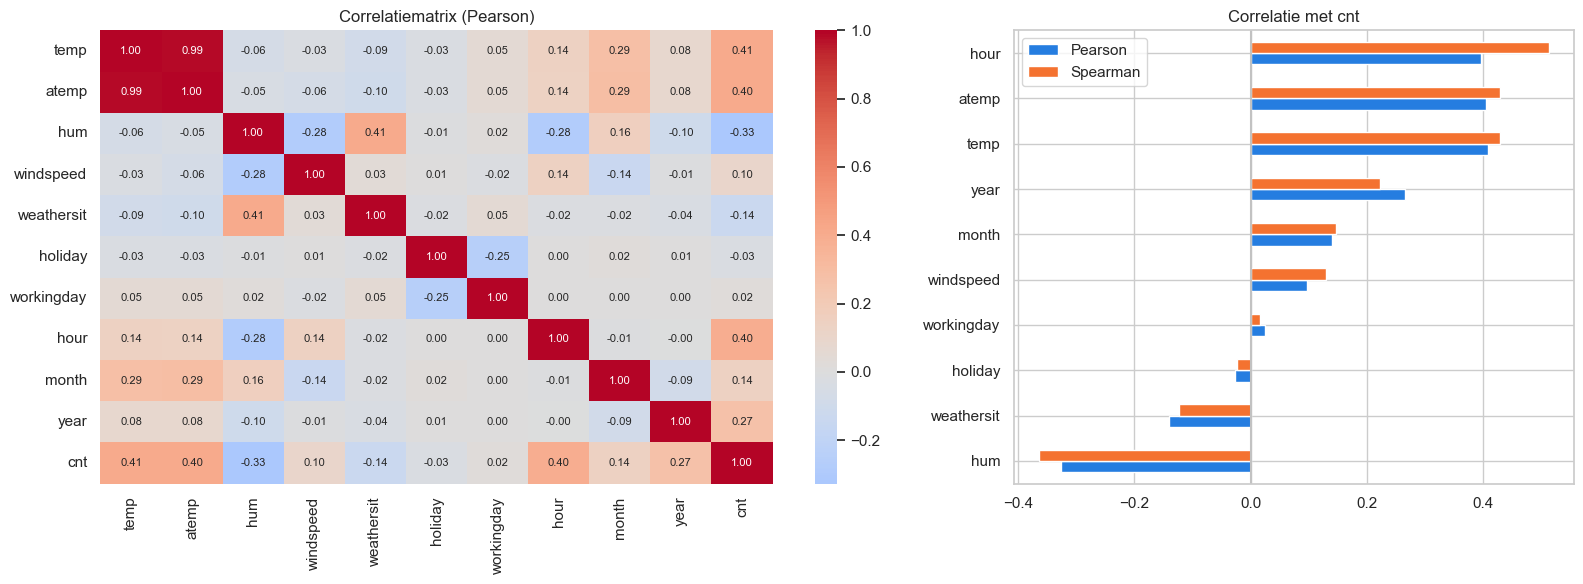

,Pearson,Spearman
hum,-0.327,-0.364
weathersit,-0.140,-0.124
holiday,-0.027,-0.024
workingday,0.025,0.016
windspeed,0.097,0.130
month,0.140,0.148
year,0.267,0.223
temp,0.409,0.429
atemp,0.405,0.430
hour,0.397,0.513


In [19]:
corr_cols = ["temp", "atemp", "hum", "windspeed", "weathersit", "holiday",
             "workingday", "hour", "month", "year", TARGET]

fig, axes = plt.subplots(1, 2, figsize=(16, 6),
                         gridspec_kw={"width_ratios": [3, 2]})
sns.heatmap(train[corr_cols].corr(), cmap="coolwarm", center=0, annot=True,
            fmt=".2f", annot_kws={"size": 8}, ax=axes[0])
axes[0].set_title("Correlatiematrix (Pearson)")

corr_target = pd.DataFrame({
    "Pearson": train[corr_cols].corr()[TARGET],
    "Spearman": train[corr_cols].corr(method="spearman")[TARGET],
}).drop(TARGET).sort_values("Spearman")
corr_target.plot(kind="barh", ax=axes[1], color=[BLUE, ORANGE])
axes[1].set_title("Correlatie met cnt")
axes[1].axvline(0, color="#c2c2c2")
plt.tight_layout()
plt.show()

corr_target.round(3)

### 2.6 Belangrijkste bevindingen

### 2.7 Data opschonen

## 3. Time series feature engineering

### 3.1 Seizoenspatronen (Fourier analyse)

### 3.2 Trends

### 3.3 Cycli en autocorrelatie

### 3.4 Andere tijdsgebaseerde features

### 3.5 Invloed van de features en uiteindelijke keuze

## 4. Modelleren

### 4.1 Aanpak: RMSE, cross-validation en hyperparameter tuning

_4.2 t/m 4.6: modellen met time series features + reguliere features (minimaal 5 modellen)._

### 4.2 Lineaire regressie

#### Uitleg
_(wiskundige uitleg, met o.a. loss function en regularisatie)_
#### Resultaten

### 4.3 Ensemble model

#### Uitleg
_(wiskundige uitleg)_
#### Resultaten

### 4.4 Model 3 (eigen keuze)

#### Uitleg
_(onderbouwing keuze)_
#### Resultaten

### 4.5 Model 4 (eigen keuze)

#### Uitleg
_(onderbouwing keuze)_
#### Resultaten

### 4.6 Model 5 (eigen keuze)

#### Uitleg
_(onderbouwing keuze)_
#### Resultaten

### 4.7 SARIMA(X)

#### Uitleg
#### Resultaten

### 4.8 Tweede tijdseriemodel (eigen keuze)

#### Uitleg
#### Resultaten

### 4.9 Hybride model

#### Uitleg
#### Resultaten

### 4.10 Voorspellingen voor Kaggle

## 5. Bevindingen

### 5.1 Samenvatting

### 5.2 Overzicht resultaten

| Model | Beste parameters | RMSE (CV) | RMSE Kaggle |
|---|---|---|---|
| Lineaire regressie | | | |
| Ensemble model | | | |
| Model 3 | | | |
| Model 4 | | | |
| Model 5 | | | |
| SARIMA(X) | | | |
| Tijdseriemodel 2 | | | |
| Hybride model | | | |

### 5.3 Welk model presteert het beste?

### 5.4 Kaggle-scores en verbeteringen

| Submission | Datum | Model / wijziging | RMSE Kaggle |
|---|---|---|---|
| 1 | | | |
| 2 | | | |
| 3 | | | |

## 6. Conclusie en aanbevelingen

### 6.1 Welke features hebben de meeste invloed?

### 6.2 Aansluiting bij de EDA

### 6.3 Advies aan CityBike

### 6.4 Welk model adviseren wij en waarom?

## 7. Referenties